# Every number in the report, recomputed from the saved results

This notebook rebuilds each results table in the report from files already in the repository
(`data/`, `results/` and the saved outputs of `notebooks/02_svm_mlp.ipynb`). It retrains nothing
except the linear SVM used to read per-word scores in Section 8 (0.1 s), so it runs on a CPU in a
few seconds. Table numbers refer to the final report.

| Report | Source of the numbers |
|---|---|
| Tables 1, 2 | `data/train.json`, `data/test.json` |
| Tables 4, 5 | saved outputs of `notebooks/02_svm_mlp.ipynb` |
| Tables 6, 10 | `results/distilbert_tuning/` and `results/distilbert_val_predictions.csv` (written by `05_distilbert_tuning.ipynb`) |
| Tables 7, 8 | `results/hyperparameter_search.csv` (written by `src/tune_hyperparameters.py`) |
| Table 12, Figures 12, 13 | the four confusion matrices below |
| Tables 13, 14 | `results/submission.csv` |
| Tables 15 to 17, Section 8 | `results/distilbert_val_predictions.csv`, `results/svm_val_predictions.csv`, `results/distilbert_test_probabilities.csv` |
| Table 20 | `results/model_comparison.json` |
| Table 22 | arithmetic |

Table 9 (the MLP sweep) is not reproduced: the sweep code is not in the repository.

In [1]:
from pathlib import Path
import base64, json, re
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.svm import LinearSVC

SEED = 42
pd.set_option('display.width', 200)
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / 'data' / 'train.json').exists())
DATA, RES = ROOT / 'data', ROOT / 'results'

train_df = pd.read_json(DATA / 'train.json')
test_df = pd.read_json(DATA / 'test.json')
# The shared split used by every model in the report
X_tr, X_va, y_tr, y_va = train_test_split(train_df['reviews'], train_df['sentiments'],
                                          test_size=0.2, random_state=SEED, stratify=train_df['sentiments'])
print('train.json', train_df.shape, '| test.json', test_df.shape)
print('split:', len(X_tr), 'training /', len(X_va), 'validation reviews')

train.json (7401, 2) | test.json (1851, 1)
split: 5920 training / 1481 validation reviews


## Section 2: dataset (Tables 1 and 2)

In [2]:
counts = train_df['sentiments'].value_counts()
words = train_df['reviews'].str.split().str.len()
test_words = test_df['reviews'].str.split().str.len()
NEGATION = r'\b(?:not|no|never)\b'

print('Table 1: Dataset summary')
print(f"  positive / negative: {counts[1]:,} ({counts[1]/len(train_df):.1%}) / {counts[0]:,} ({counts[0]/len(train_df):.1%})")
print(f"  training split: {len(X_tr):,} reviews, {(y_tr == 0).sum()} negative")
print(f"  validation split: {len(X_va):,} reviews, {(y_va == 0).sum()} negative")
print(f"  words per review: median {words.median():.0f}, 95th percentile {words.quantile(0.95):.0f}, max {words.max():,}")
print(f"  median words: negative {words[train_df['sentiments'] == 0].median():.0f}, "
      f"positive {words[train_df['sentiments'] == 1].median():.0f}, test {test_words.median():.0f}")
print(f"  reviews of 256 words or fewer: {(words <= 256).mean():.1%}")
print(f"  reviews containing not / no / never: {train_df['reviews'].str.contains(NEGATION, case=False).mean():.1%}")
print(f"  size of the English stop-word list: {len(ENGLISH_STOP_WORDS)}")

Table 1: Dataset summary
  positive / negative: 6,319 (85.4%) / 1,082 (14.6%)
  training split: 5,920 reviews, 865 negative
  validation split: 1,481 reviews, 217 negative
  words per review: median 42, 95th percentile 143, max 1,066
  median words: negative 50, positive 41, test 40
  reviews of 256 words or fewer: 98.8%
  reviews containing not / no / never: 35.8%
  size of the English stop-word list: 318


In [3]:
repeats = train_df['reviews'].duplicated(keep=False)
test_overlap = test_df['reviews'].isin(set(train_df['reviews']))
val_in_train = X_va.isin(set(X_tr))
non_ascii = lambda s: s.map(lambda t: any(ord(c) > 127 for c in t)).sum()
with_url = lambda s: s.str.contains(r'https?://|www\.').sum()

print('Table 2: Data checks')
print(f"  texts that appear more than once: {train_df.loc[repeats, 'reviews'].nunique()}, "
      f"extra copies: {train_df['reviews'].duplicated().sum()}, most copies of one text: {train_df['reviews'].value_counts().max()}")
print(f"  texts with conflicting labels: {(train_df.groupby('reviews')['sentiments'].nunique() > 1).sum()}")
print(f"  validation reviews also in the training split: {val_in_train.sum()} ({val_in_train.mean():.1%})")
print(f"  test rows also in train.json: {test_overlap.sum()} ({test_overlap.mean():.1%}), "
      f"{test_df.loc[test_overlap, 'reviews'].nunique()} distinct texts")
print(f"  repeated rows in test.json: {test_df['reviews'].duplicated().sum()}")
print(f"  non-ASCII reviews: train {non_ascii(train_df['reviews'])}, test {non_ascii(test_df['reviews'])}")
print(f"  reviews with URLs: train {with_url(train_df['reviews'])}, test {with_url(test_df['reviews'])}")
print(f"  reviews with HTML tags: {train_df['reviews'].str.contains(r'<[a-zA-Z/][^>]*>').sum()}")

Table 2: Data checks
  texts that appear more than once: 151, extra copies: 216, most copies of one text: 5
  texts with conflicting labels: 0
  validation reviews also in the training split: 73 (4.9%)
  test rows also in train.json: 101 (5.5%), 87 distinct texts
  repeated rows in test.json: 21


  non-ASCII reviews: train 18, test 4
  reviews with URLs: train 2, test 1
  reviews with HTML tags: 0


## Sections 3 and 4: linear SVM and MLP (Tables 4 and 5)

The report quotes the run saved in `notebooks/02_svm_mlp.ipynb` (Anaconda, Python 3.12). Re-running it
with a newer scikit-learn changes the scores slightly (see the library-version note in `README.md`),
so this cell prints the saved outputs of that notebook instead of retraining.

In [4]:
nb02 = json.loads((ROOT / 'notebooks' / '02_svm_mlp.ipynb').read_text(encoding='utf-8'))
for cell in nb02['cells']:
    for out in cell.get('outputs', []):
        text = ''.join(out.get('text', [])) or ''.join(out.get('data', {}).get('text/plain', []))
        if 'training time' in text or 'Validation accuracy' in text:
            print(text.rstrip(), end='\n\n')

SVM training time (s): 0.11
              precision    recall  f1-score   support

    negative       0.80      0.71      0.76       217
    positive       0.95      0.97      0.96      1264

    accuracy                           0.93      1481
   macro avg       0.88      0.84      0.86      1481
weighted avg       0.93      0.93      0.93      1481

MLP training time (s): 4.6
Epochs used: 17
              precision    recall  f1-score   support

    negative       0.74      0.60      0.67       217
    positive       0.93      0.96      0.95      1264

    accuracy                           0.91      1481
   macro avg       0.84      0.78      0.81      1481
weighted avg       0.91      0.91      0.91      1481

                Model  Validation accuracy  Macro F1  Negative F1  \
0          Linear SVM               0.9325    0.8585       0.7561   
1  MLP (TF-IDF + SVD)               0.9115    0.8078       0.6667   

   Train seconds  
0         0.1076  
1         4.5988



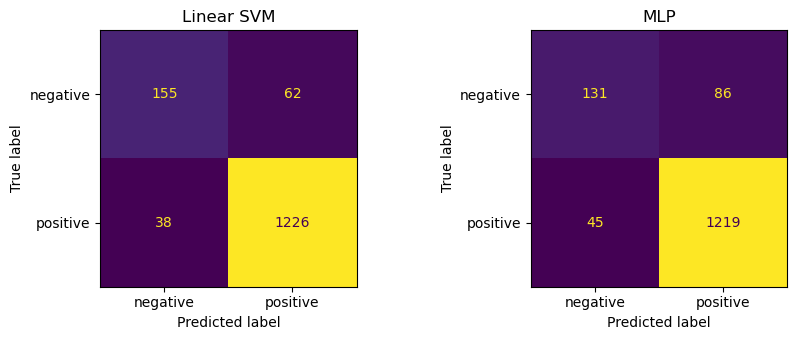

In [5]:
# The confusion matrices of that same run, saved as a figure in 02_svm_mlp.ipynb
from IPython.display import Image, display
png = next(out['data']['image/png'] for cell in nb02['cells'] for out in cell.get('outputs', [])
           if 'image/png' in out.get('data', {}) and 'ConfusionMatrixDisplay' in ''.join(cell['source']))
display(Image(data=base64.b64decode(png)))

## Sections 5 and 6.3: DistilBERT (Tables 6 and 10)

In [6]:
tuning = pd.read_csv(RES / 'distilbert_tuning' / 'tuning_results.csv')
tuning['lr'] = tuning['lr'].map(lambda v: f'{v:g}')
best = tuning.set_index('run').loc['baseline']   # the final model: lr 2e-5, seed 42

def report_rows(tn, fp, fn, tp):
    # Per-class precision / recall / F1 from a confusion matrix (negative = class 0)
    rows = {}
    for name, t, f_pred_other, f_true_other, n in [
            ('Negative (0)', tn, fn, fp, tn + fp),    # caught, false alarms, missed
            ('Positive (1)', tp, fp, fn, tp + fn)]:
        p = t / (t + f_pred_other); r = t / (t + f_true_other)
        rows[name] = dict(precision=p, recall=r, f1=2 * p * r / (p + r), support=n)
    df = pd.DataFrame(rows).T
    n = df['support'].sum()
    df.loc['Macro average'] = [*df[['precision', 'recall', 'f1']].mean(), n]
    df.loc['Weighted average'] = [*(df.iloc[:2][['precision', 'recall', 'f1']].mul(df.iloc[:2]['support'], axis=0).sum() / n), n]
    return df, (tn + tp) / n

table6, acc = report_rows(best.tn, best.fp, best.fn, best.tp)
print('Table 6: DistilBERT validation report (best checkpoint, epoch', best.best_epoch, ')')
print(table6.round(3).to_string()); print('accuracy', round(acc, 3))
print(f"\nnegatives caught: {best.tn} of {best.tn + best.fp}; false alarms: {best.fn}")
print(f"training: {best.train_seconds} s, peak GPU memory {best.peak_gpu_gb} GB")
hist = pd.read_csv(RES / 'distilbert_tuning' / 'baseline_history.csv')
print('\nvalidation macro F1 by epoch (baseline):', hist['macro_f1'].round(4).tolist())

Table 6: DistilBERT validation report (best checkpoint, epoch 2 )
                  precision  recall     f1  support
Negative (0)          0.843   0.816  0.829    217.0
Positive (1)          0.969   0.974  0.971   1264.0
Macro average         0.906   0.895  0.900   1481.0
Weighted average      0.950   0.951  0.950   1481.0
accuracy 0.951

negatives caught: 177 of 217; false alarms: 33
training: 227.8 s, peak GPU memory 2.49 GB

validation macro F1 by epoch (baseline): [0.8866, 0.9001, 0.8989, 0.8978]


In [7]:
cols = ['run', 'lr', 'class_weighted', 'seed', 'best_epoch', 'accuracy', 'macro_f1', 'neg_precision', 'neg_recall', 'neg_f1']
print('Table 10: DistilBERT tuning runs')
print(tuning[cols].round(4).to_string(index=False))

print('\nThree-seed means (seeds 42, 1, 2), mean ± sample std:')
plain = tuning[~tuning['class_weighted']]
for lr, g in plain.groupby('lr'):
    if len(g) == 3:
        print(f"  lr {lr}: accuracy {g.accuracy.mean():.4f} ± {g.accuracy.std():.4f} | "
              f"macro F1 {g.macro_f1.mean():.4f} ± {g.macro_f1.std():.4f} | negative F1 {g.neg_f1.mean():.4f}")

Table 10: DistilBERT tuning runs
           run    lr  class_weighted  seed  best_epoch  accuracy  macro_f1  neg_precision  neg_recall  neg_f1
      baseline 2e-05           False    42           2    0.9507    0.9001         0.8429      0.8157  0.8290
class_weighted 2e-05            True    42           4    0.9433    0.8891         0.7904      0.8341  0.8117
       lr_3e-5 3e-05           False    42           2    0.9500    0.9005         0.8265      0.8341  0.8303
       lr_5e-5 5e-05           False    42           2    0.9494    0.9016         0.8060      0.8618  0.8330
baseline_seed1 2e-05           False     1           3    0.9534    0.9067         0.8426      0.8387  0.8406
 lr_5e-5_seed1 5e-05           False     1           3    0.9453    0.8913         0.8091      0.8203  0.8146
baseline_seed2 2e-05           False     2           4    0.9433    0.8891         0.7904      0.8341  0.8117
 lr_5e-5_seed2 5e-05           False     2           3    0.9446    0.8901         0.80

In [8]:
# Decision threshold (Section 6.3), using the final model's saved validation probabilities
val = pd.read_csv(RES / 'distilbert_val_predictions.csv')
from sklearn.metrics import confusion_matrix, f1_score
pred = (val['prob_positive'] >= 0.5).astype(int)
print('these probabilities reproduce the final confusion matrix:', confusion_matrix(val['true'], pred, labels=[0, 1]).ravel().tolist())
base_f1 = f1_score(val['true'], pred, average='macro')
for t in np.arange(0.30, 0.701, 0.05):
    f1 = f1_score(val['true'], (val['prob_positive'] >= t).astype(int), average='macro')
    print(f"  threshold {t:.2f}: macro F1 {f1:.4f} (change {f1 - base_f1:+.4f})")

these probabilities reproduce the final confusion matrix: [177, 40, 33, 1231]
  threshold 0.30: macro F1 0.9054 (change +0.0052)
  threshold 0.35: macro F1 0.9089 (change +0.0088)
  threshold 0.40: macro F1 0.9033 (change +0.0032)
  threshold 0.45: macro F1 0.9025 (change +0.0024)
  threshold 0.50: macro F1 0.9001 (change +0.0000)
  threshold 0.55: macro F1 0.8993 (change -0.0008)
  threshold 0.60: macro F1 0.9001 (change -0.0000)
  threshold 0.65: macro F1 0.8993 (change -0.0008)
  threshold 0.70: macro F1 0.8997 (change -0.0004)


## Section 6.1: SVM and TF-IDF settings (Tables 7 and 8)

In [9]:
hp = pd.read_csv(RES / 'hyperparameter_search.csv', keep_default_na=False)   # keep 'None' as text
svm = hp[hp['model'] == 'Linear SVM']
print('Table 7: Linear SVM, effect of C')
print(svm[svm['knob'] == 'C'][['value', 'accuracy', 'macro_f1', 'negative_f1']].round(4).to_string(index=False))
print('\nTable 8: Linear SVM, TF-IDF settings (macro F1; chosen = kept)')
print(svm[svm['knob'] != 'C'][['knob', 'value', 'chosen', 'features', 'macro_f1', 'macro_f1_delta']].round(4).to_string(index=False))

Table 7: Linear SVM, effect of C
value  accuracy  macro_f1  negative_f1
 0.01    0.8778    0.7953       0.6654
  0.1    0.9095    0.8340       0.7220
  1.0    0.9325    0.8579       0.7549
 10.0    0.9284    0.8428       0.7268
100.0    0.9257    0.8362       0.7150

Table 8: Linear SVM, TF-IDF settings (macro F1; chosen = kept)
        knob    value  chosen  features  macro_f1  macro_f1_delta
max_features     5000   False      5000    0.8321         -0.0258
max_features    10000   False     10000    0.8459         -0.0120
max_features    20000    True     20000    0.8579          0.0000
max_features    50000   False     20873    0.8579          0.0000
max_features     None   False     20873    0.8579          0.0000
 ngram_range   (1, 1)   False      6290    0.8257         -0.0322
 ngram_range   (1, 2)    True     20000    0.8579          0.0000
 ngram_range   (1, 3)   False     20000    0.8545         -0.0034
      min_df        1   False     20000    0.8545         -0.0034
      min

## Section 7: all four models (Table 12, Figures 12 and 13)

Every metric in Table 12 follows from the four confusion matrices, so they are listed with their sources
and the table is computed from them.

In [10]:
comparison = {m['short']: m for m in json.loads((RES / 'model_comparison.json').read_text())['models']}
lr_cm = comparison['LogReg']['confusion_matrix'] if 'LogReg' in comparison else next(
    m['confusion_matrix'] for m in comparison.values() if 'Logistic' in m['name'])

# (negatives caught, negatives missed, false alarms, positives correct)
cms = {
    'Logistic regression': (lr_cm['tn'], lr_cm['fp'], lr_cm['fn'], lr_cm['tp']),   # results/model_comparison.json
    'Linear SVM': (155, 62, 38, 1226),   # 02_svm_mlp.ipynb, confusion-matrix figure above
    'MLP': (131, 86, 45, 1219),          # 02_svm_mlp.ipynb, confusion-matrix figure above
    'DistilBERT': (best.tn, best.fp, best.fn, best.tp),   # results/distilbert_tuning/tuning_results.csv
}
rows = {}
for name, (tn, fp, fn, tp) in cms.items():
    rep, acc = report_rows(tn, fp, fn, tp)
    rows[name] = {'Accuracy': acc, 'Macro F1': rep.loc['Macro average', 'f1'], 'Weighted F1': rep.loc['Weighted average', 'f1'],
                  'Neg P': rep.loc['Negative (0)', 'precision'], 'Neg R': rep.loc['Negative (0)', 'recall'], 'Neg F1': rep.loc['Negative (0)', 'f1'],
                  'Pos P': rep.loc['Positive (1)', 'precision'], 'Pos R': rep.loc['Positive (1)', 'recall'], 'Pos F1': rep.loc['Positive (1)', 'f1']}
print('Table 12: validation results (two decimals in the report)')
print(pd.DataFrame(rows).round(4).to_string())

print('\nFigure 12: negatives caught / missed / false alarms')
for name, (tn, fp, fn, tp) in cms.items():
    print(f"  {name:20s} caught {tn:3d}  missed {fp:3d}  false alarms {fn:3d}")

always_pos = (y_va == 1).mean()
print(f"\nalways predicting positive: accuracy {always_pos:.3f}, macro F1 {(2 * always_pos / (1 + always_pos)) / 2:.2f}")

Table 12: validation results (two decimals in the report)
             Logistic regression  Linear SVM     MLP  DistilBERT
Accuracy                  0.9095      0.9325  0.9115      0.9507
Macro F1                  0.8334      0.8585  0.8078      0.9001
Weighted F1               0.9130      0.9308  0.9076      0.9504
Neg P                     0.6578      0.8031  0.7443      0.8429
Neg R                     0.7972      0.7143  0.6037      0.8157
Neg F1                    0.7208      0.7561  0.6667      0.8290
Pos P                     0.9639      0.9519  0.9341      0.9685
Pos R                     0.9288      0.9699  0.9644      0.9739
Pos F1                    0.9460      0.9608  0.9490      0.9712

Figure 12: negatives caught / missed / false alarms
  Logistic regression  caught 173  missed  44  false alarms  90
  Linear SVM           caught 155  missed  62  false alarms  38
  MLP                  caught 131  missed  86  false alarms  45
  DistilBERT           caught 177  missed  40  

## Section 7.2: test predictions (Tables 13 and 14)

In [11]:
sub = pd.read_csv(RES / 'submission.csv')
example = pd.read_csv(DATA / 'submission_example.csv')
print('columns:', list(sub.columns), '| matches submission_example.csv:', list(sub.columns) == list(example.columns))
print('rows:', len(sub), '| reviews identical to test.json, row by row:', bool((sub['reviews'] == test_df['reviews']).all()))
print('every prediction is 0 or 1:', bool(sub['predictions'].isin([0, 1]).all()))
n_pos = int(sub['predictions'].sum())
print(f"positive {n_pos} ({n_pos / len(sub):.1%}), negative {len(sub) - n_pos}")
print('\nTable 14: first five rows')
print(sub.head().assign(reviews=sub['reviews'].str[:70] + '...').to_string())

columns: ['reviews', 'predictions'] | matches submission_example.csv: True
rows: 1851 | reviews identical to test.json, row by row: True
every prediction is 0 or 1: True
positive 1613 (87.1%), negative 238

Table 14: first five rows
                                                                     reviews  predictions
0  I bought 2 sleepers.  sleeper had holes in the arm pit area and the ot...            0
1  I dare say these are just about the sexiest things I've ever worn. Oh ...            1
2  everything about the transaction (price, delivery time, quality of ite...            1
3  Not bad for just a shirt.  Very durable, and matched my teams colors p...            1
4  These are truly wrinkle free and longer than the average womans botton...            1


## Section 8: error analysis (Tables 15 to 17 and the test-set check)

In [12]:
svm_val = pd.read_csv(RES / 'svm_val_predictions.csv')   # src/svm_val_predictions.py, same split
assert (svm_val['reviews'] == val['reviews']).all()
bert_right = (val['prob_positive'] >= 0.5).astype(int) == val['true']
svm_right = svm_val['correct']
print('Table 15: agreement on the 1,481 validation reviews')
for label, mask in [('both right', bert_right & svm_right), ('both wrong', ~bert_right & ~svm_right),
                    ('only DistilBERT right', bert_right & ~svm_right), ('only the SVM right', ~bert_right & svm_right)]:
    print(f"  {label:22s} {mask.sum():5d}  ({mask.mean():.1%})")

only_bert_neg = val[bert_right & ~svm_right & (val['true'] == 0)]
print(f"\nnegative reviews only DistilBERT gets right: {len(only_bert_neg)}, "
      f"of which contain not / no / never: {only_bert_neg['reviews'].str.contains(NEGATION, case=False).sum()}")

Table 15: agreement on the 1,481 validation reviews


  both right              1341  (90.5%)
  both wrong                33  (2.2%)
  only DistilBERT right     67  (4.5%)
  only the SVM right        40  (2.7%)

negative reviews only DistilBERT gets right: 40, of which contain not / no / never: 25


In [13]:
# Tables 16 and 17: the quoted reviews, with DistilBERT's probability and the SVM's decision score
cases = ['Not Happy at all', 'I am a little dissapointed', 'It took them weeks', 'Dilvered quickly', 'Bra was more padded']
for snippet in cases:
    i = val.index[val['reviews'].str.contains(snippet, regex=False)][0]
    print(f"{snippet!r}: true {val.loc[i, 'true']} | DistilBERT P(pos) {val.loc[i, 'prob_positive']:.3f} | "
          f"SVM score {svm_val.loc[i, 'decision_score']:+.2f}")

'Not Happy at all': true 0 | DistilBERT P(pos) 0.010 | SVM score +0.80
'I am a little dissapointed': true 0 | DistilBERT P(pos) 0.022 | SVM score +0.33
'It took them weeks': true 1 | DistilBERT P(pos) 0.011 | SVM score -0.95
'Dilvered quickly': true 0 | DistilBERT P(pos) 0.998 | SVM score +1.82
'Bra was more padded': true 1 | DistilBERT P(pos) 0.066 | SVM score +1.09


In [14]:
# Per-word SVM scores (TF-IDF weight x SVM coefficient), from the same SVM settings as the report
vec = TfidfVectorizer(lowercase=True, stop_words='english', ngram_range=(1, 2), min_df=2, max_features=20000)
X = vec.fit_transform(X_tr.fillna(''))
svm_model = LinearSVC(C=1.0, class_weight='balanced', random_state=SEED, max_iter=5000).fit(X, y_tr)
vocab = vec.get_feature_names_out()
print('SVM weight: dissapointed', round(float(svm_model.coef_[0, vec.vocabulary_['dissapointed']]), 2),
      '| disappointed', round(float(svm_model.coef_[0, vec.vocabulary_['disappointed']]), 2))

def word_scores(text, n=4):
    row = vec.transform([text])
    contrib = [(str(vocab[j]), round(float(row[0, j] * svm_model.coef_[0, j]), 2)) for j in row.nonzero()[1]]
    return sorted(contrib, key=lambda kv: -abs(kv[1]))[:n]

for snippet in ['Not Happy at all', 'It took them weeks', 'Bra was more padded']:
    print(f"{snippet!r}:", word_scores(val.loc[val['reviews'].str.contains(snippet, regex=False), 'reviews'].iloc[0]))

SVM weight: dissapointed -1.3 | disappointed -2.58
'Not Happy at all': [('happy', 0.56), ('shot', 0.13), ('inside', -0.11), ('buy', -0.09)]
'It took them weeks': [('bad', -0.24), ('item', -0.23), ('took weeks', -0.2), ('customer', -0.18)]
'Bra was more padded': [('love', 0.48), ('adequate', 0.24), ('thought', -0.21), ('shopping', 0.17)]


In [15]:
# Test-set check: test rows whose text also appears, with a label, in train.json
test_prob = pd.read_csv(RES / 'distilbert_test_probabilities.csv')
labels = train_df.drop_duplicates('reviews').set_index('reviews')['sentiments']
known = test_df['reviews'].isin(labels.index)
agree = sub.loc[known, 'predictions'].values == labels.loc[test_df.loc[known, 'reviews']].values
unseen = test_df.loc[known, 'reviews'].isin(set(X_va)) & ~test_df.loc[known, 'reviews'].isin(set(X_tr))
print(f"test rows with a known label: {known.sum()} | DistilBERT agrees: {agree.sum()}")
print(f"of these, never seen in training: {unseen.sum()} | DistilBERT agrees: {agree[unseen.values].sum()}")
for text in test_df.loc[known, 'reviews'][~agree]:
    i = test_df.index[test_df['reviews'] == text][0]
    print(f"\nmiss: {text!r}\n  label {labels[text]} | P(pos) {test_prob.loc[i, 'prob_positive']:.3f} | in training split: {text in set(X_tr)}")

i = test_df.index[test_df['reviews'].str.startswith('Not bad for just a shirt')][0]
print(f"\n'Not bad for just a shirt': P(pos) {test_prob.loc[i, 'prob_positive']:.3f} | SVM word scores {word_scores(test_df.loc[i, 'reviews'], 2)}")

test rows with a known label: 101 | DistilBERT agrees: 100
of these, never seen in training: 19 | DistilBERT agrees: 19

miss: 'The soles of these shoes are very comfortable but the padded collar of the shoes need to be broken in very well.'
  label 0 | P(pos) 0.877 | in training split: True

'Not bad for just a shirt': P(pos) 0.998 | SVM word scores [('bad', -0.29), ('perfectly', 0.24)]


## Section 9: computational resources (Table 20)

In [16]:
info = json.loads((RES / 'model_comparison.json').read_text())
f = info['features']
print(f"TF-IDF matrix: {f['train_shape']}, {f['active_terms_per_review']:.0f} non-zero terms per review, "
      f"{f['sparse_mb']} MB sparse vs {f['dense_mb_if_dense']:.0f} MB if dense")
print(f"SVD features: 5,920 x 200 x 8 bytes = {5920 * 200 * 8 / 1e6:.2f} MB dense")
for m in info['models']:
    print(f"  {m['name']:40s} parameters {m['parameters']:>11,}")
print('MLP parameters in the SVD projection: 20,000 x 200 =', f"{20000 * 200:,}")
print('training time: SVM 0.11 s and MLP 4.6 s (02_svm_mlp.ipynb, above); logistic regression',
      next(m['train_seconds'] for m in info['models'] if 'Logistic' in m['name']), 's; DistilBERT', best.train_seconds, 's')

TF-IDF matrix: [5920, 20000], 29 non-zero terms per review, 2.09 MB sparse vs 947 MB if dense
SVD features: 5,920 x 200 x 8 bytes = 9.47 MB dense
  TF-IDF + Logistic Regression             parameters      20,001
  TF-IDF + Linear SVM                      parameters      20,001
  TF-IDF + SVD(200) + MLP(128, 64)         parameters   4,034,049
  DistilBERT (4 epochs, max_length=256)    parameters  66,955,010
MLP parameters in the SVD projection: 20,000 x 200 = 4,000,000
training time: SVM 0.11 s and MLP 4.6 s (02_svm_mlp.ipynb, above); logistic regression 0.169 s; DistilBERT 227.8 s


## Section 11: label-noise illustration (Table 22)

In [17]:
pos, neg, flip = 850, 150, 0.05
pos_to_neg, neg_to_pos = round(pos * flip), round(neg * flip)   # 42 (42.5 rounded down) and 8 (7.5 rounded up)
labelled_neg = neg - neg_to_pos + pos_to_neg
labelled_pos = pos - pos_to_neg + neg_to_pos
print(f"labelled positive: {labelled_pos}, wrong {neg_to_pos} ({neg_to_pos / labelled_pos:.0%})")
print(f"labelled negative: {labelled_neg}, wrong {pos_to_neg} ({pos_to_neg / labelled_neg:.0%})")

labelled positive: 816, wrong 8 (1%)
labelled negative: 184, wrong 42 (23%)
